In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import percentileofscore

#daily newly established equity-oriented fund shares
fund = pd.read_stata('daily fund shares.dta')
fund.columns = ['fundcode', 'scale', 'date']
fund['date'] = pd.to_datetime(fund['date'])
fund['year'] = fund['date'].dt.year
fund['month'] = fund['date'].dt.month
fund_monthly = fund.groupby(['year', 'month'])['scale'].mean() #use mean or else explode

#daily csi 300 pe and dividend yield
csi = pd.read_stata('CSI300 PE and dividend yield.dta')
csi.columns = ['date', 'csi300_pe', 'csi300_div_yield']
csi['date'] = pd.to_datetime(csi['date'])

#daily prices for representative stocks
price = pd.read_stata('daily representative price.dta')
price.columns = ['stk_code', 'date', 'price']
price['date'] = pd.to_datetime(price['date'])

#daily total value of shares traded
trading = pd.read_excel('TRD_Dalym.xlsx', header = None, skiprows = 3)
trading.columns = ['market_type', 'date', 'trading_value']
trading['date'] = pd.to_datetime(trading['date'])
trading['trading_value'] = pd.to_numeric(trading['trading_value'], errors='coerce')

def load_index(filepath):
    df = pd.read_excel(filepath, header=None, skiprows=3)
    df.columns = ['index_code', 'date', 'open_idx', 'high_idx', 'low_idx', 'close_idx', 'volume']
    df['date'] = pd.to_datetime(df['date'])
    for col in ['open_idx', 'high_idx', 'low_idx', 'close_idx', 'volume']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

#sse composite index daily price (each has 4 years, combine files)
index1 = load_index('IDX_Idxtrd.xlsx')
index2 = load_index('IDX_Idxtrd2.xlsx')
index3 = load_index('IDX_Idxtrd3.xlsx')
index4 = load_index('IDX_Idxtrd4.xlsx')

index_combined = pd.concat([index1, index2, index3, index4], ignore_index=True)
index_combined = index_combined[index_combined['index_code'] == 1]
index_combined = index_combined.drop_duplicates(subset=['date']).sort_values('date').reset_index(drop=True)

#daily margin trading and securities lending balance
margin = pd.read_excel('CHN_Stkmt_dsummary.xlsx', header=None, skiprows=3)
margin.columns = ['exchange_code', 'date', 'finance_balance', 'secshort_balance', 'short_balance', 'mt_balance']
margin['date'] = pd.to_datetime(margin['date'])
margin['mt_balance'] = pd.to_numeric(margin['mt_balance'], errors='coerce')
margin_daily = margin.groupby('date')['mt_balance'].sum().reset_index()

#daily 10-year government bond yield
bond = pd.read_excel('BND_TreasYield.xlsx', header=None, skiprows=3)
bond.columns = ['date', 'cvtype', 'yeartomatu', 'yield']
bond['date'] = pd.to_datetime(bond['date'])
bond['yield'] = pd.to_numeric(bond['yield'], errors='coerce')
bond_10y = bond[bond['yeartomatu'] == 10].copy()
bond_10y = bond_10y[['date', 'yield']].drop_duplicates(subset=['date']).sort_values('date').reset_index(drop=True)

for df in [fund, csi, price, trading, index1, index2, index3, index4, margin, bond]:
    print(df.head())

/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default sty

    fundcode    scale       date  year  month
0  161601.OF  22.1886 2002-08-15  2002      8
1  080001.OF  31.6689 2002-08-26  2002      8
2  070001.OF  20.0191 2002-09-30  2002      9
3  217001.OF  10.2919 2003-03-17  2003      3
4  070002.OF   9.4534 2003-06-02  2003      6
        date  csi300_pe  csi300_div_yield
0 2005-04-08      15.60              1.83
1 2005-04-09      15.61              1.83
2 2005-04-10      15.61              1.83
3 2005-04-11      15.50              1.85
4 2005-04-12      15.13              1.90
  stk_code       date  price
0   000166 2015-01-26  19.65
1   000166 2015-01-27  17.73
2   000166 2015-01-28  17.17
3   000166 2015-01-29  17.60
4   000166 2015-01-30  16.85
   market_type       date  trading_value
0           16 2014-01-02   2.885939e+10
1            2 2014-01-02   1.368160e+07
2            8 2014-01-02   1.402879e+08
3            4 2014-01-02   6.702423e+10
4            1 2014-01-02   6.183783e+10
   index_code       date  open_idx  high_idx   low_i

In [21]:
trading_aggregated = trading.groupby('date')['trading_value'].sum().reset_index()
trading_aggregated = trading_aggregated.sort_values('date').reset_index(drop=True)

print(f"\nTrading data: {len(trading_aggregated)} unique dates from {trading_aggregated['date'].min()} to {trading_aggregated['date'].max()}")


Trading data: 2973 unique dates from 2014-01-02 00:00:00 to 2026-03-27 00:00:00


In [22]:
#east money (300059)
east_money = price[price['stk_code'] == 300059].copy()
if len(east_money) == 0:
    east_money = price[price['stk_code'] == '300059'].copy()
east_money = east_money.rename(columns={'price': 'east_money_price'})
east_money = east_money[['date', 'east_money_price']]

#hundsun (600570)
hundsun = price[price['stk_code'] == 600570].copy()
if len(hundsun) == 0:
    hundsun = price[price['stk_code'] == '600570'].copy()
hundsun = hundsun.rename(columns={'price': 'hundsun_price'})
hundsun = hundsun[['date', 'hundsun_price']]

print(f"East Money: {len(east_money)} rows")
print(f"Hundsun: {len(hundsun)} rows")

East Money: 3584 rows
Hundsun: 3580 rows


In [23]:
all_dates = pd.Series(pd.concat([
    trading_aggregated['date'],
    index_combined['date'],
    margin_daily['date'],
    bond_10y['date'],
    csi['date'],
    east_money['date'],
    hundsun['date']
]).unique()).sort_values()

print(f"\nTotal unique dates: {len(all_dates)}")

master = pd.DataFrame({'date': all_dates})

#merge everything
master = master.merge(trading_aggregated[['date', 'trading_value']], on='date', how='left')
master = master.merge(index_combined[['date', 'close_idx']], on='date', how='left')
master = master.merge(margin_daily[['date', 'mt_balance']], on='date', how='left')
master = master.merge(bond_10y[['date', 'yield']], on='date', how='left')
master = master.merge(csi[['date', 'csi300_pe', 'csi300_div_yield']], on='date', how='left')
master = master.merge(east_money, on='date', how='left')
master = master.merge(hundsun, on='date', how='left')
master = master.sort_values('date').reset_index(drop=True)

#forward fill
numeric_cols = ['trading_value', 'close_idx', 'mt_balance', 'yield',
                'csi300_pe', 'csi300_div_yield', 'east_money_price', 'hundsun_price']

for col in numeric_cols:
    if col in master.columns:
        master[col] = master[col].fillna(method='ffill')

print(f"Master shape: {master.shape}")
print(f"Date range: {master['date'].min()} to {master['date'].max()}")


Total unique dates: 7909
Master shape: (7909, 9)
Date range: 2004-04-08 00:00:00 to 2026-04-01 00:00:00


/tmp/ipykernel_3227/2964741232.py:31: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  master[col] = master[col].fillna(method='ffill')


In [24]:
def get_value_at_date(df, target_date, column):
    """Get value at or before target date"""
    mask = (df['date'] <= target_date) & (df[column].notna())
    if mask.any():
        return df.loc[mask, column].iloc[-1]
    return np.nan

In [25]:
def get_monthly_fund_value(year, month):
    """Get fund issuance for a specific month"""
    try:
        return fund_monthly.loc[(year, month)]
    except KeyError:
        return np.nan

In [26]:
periods = {
    '2015': {'start': pd.to_datetime('2014-06-19'), 'end': pd.to_datetime('2015-06-12')},
    '2021': {'start': pd.to_datetime('2019-01-04'), 'end': pd.to_datetime('2021-02-18')},
    'current': {'start': pd.to_datetime('2024-09-18'), 'end': pd.to_datetime('2026-03-09')}
}

In [ ]:
results = {}

for period_name, dates in periods.items():
  print(f"\n {period_name} period: ")
  start_date = dates['start']
  end_date = dates['end']
  period_data = master[(master['date'] >= start_date) & (master['date'] <= end_date)]

  trading_start = get_value_at_date(master, start_date, 'trading_value')
  trading_end = get_value_at_date(master, end_date, 'trading_value')
  trading_max = period_data['trading_value'].max() if len(period_data) > 0 else np.nan

  if pd.notna(trading_start) and trading_start != 0:
    indicator1 = trading_end / trading_start #trading value ratio (1)
    indicator2 = trading_max / trading_start #maximum trading value ratio within the bull market (2a)
  else:
    indicator1 = np.nan
    indicator2 = np.nan

  #indicator1 = trading_end / trading_start if trading_start and trading_start != 0 else np.nan
  #indicator2 = trading_max / trading_start if trading_start and trading_start != 0 else np.nan

#compare sse composite index (2b)
  if len(period_data) > 0 and not period_data['trading_value'].isna().all():
        peak_date = period_data.loc[period_data['trading_value'].idxmax(), 'date']
        price_start = get_value_at_date(master, start_date, 'close_idx')
        price_peak = get_value_at_date(master, peak_date, 'close_idx')
        price_end = get_value_at_date(master, end_date, 'close_idx')

        change_before = (price_peak / price_start - 1) * 100 if price_start and price_start != 0 else np.nan
        change_after = (price_end / price_peak - 1) * 100 if price_peak and price_peak != 0 else np.nan
  else:
        change_before = np.nan
        change_after = np.nan
        peak_date = None

#margin trading balance ratio (3)
  margin_start = get_value_at_date(master, start_date, 'mt_balance')
  margin_end = get_value_at_date(master, end_date, 'mt_balance')
  indicator3 = margin_end / margin_start if margin_start and margin_start != 0 else np.nan #margin trading balance ratio (4a)

  if period_name == 'current':
      fund_end = get_monthly_fund_value(2026, 2) #4b (use Feb 2026 as end month)
  else:
      fund_end = get_monthly_fund_value(end_date.year, end_date.month) #4c (get nearest if not available)

  fund_start = get_monthly_fund_value(start_date.year, start_date.month)
  indicator4 = fund_end / fund_start if fund_start and fund_start != 0 else np.nan #new issuance of equity-oriented funds (monthly)

  pe_start = get_value_at_date(master, start_date, 'csi300_pe')
  pe_end = get_value_at_date(master, end_date, 'csi300_pe')
  bond_start = get_value_at_date(master, start_date, 'yield')
  bond_end = get_value_at_date(master, end_date, 'yield')

  bond_start_dec = bond_start / 100 if bond_start and bond_start > 1 else bond_start
  bond_end_dec = bond_end / 100 if bond_end and bond_end > 1 else bond_end

  #csi 300 erp (5)
  erp_start = (1 / pe_start) - bond_start_dec if pe_start and pe_start != 0 else np.nan
  erp_end = (1 / pe_end) - bond_end_dec if pe_end and pe_end != 0 else np.nan

  hist_end_date = start_date - pd.Timedelta(days=1)
  hist_data = master[(master['date'] >= '2005-01-01') & (master['date'] <= hist_end_date)].copy()
  hist_data['erp'] = (1 / hist_data['csi300_pe']) - (hist_data['yield'] / 100)
  hist_data = hist_data.dropna(subset=['erp'])

  if len(hist_data) > 0:
      erp_start_percentile = percentileofscore(hist_data['erp'], erp_start)
      erp_end_percentile = percentileofscore(hist_data['erp'], erp_end)
  else:
      erp_start_percentile = erp_end_percentile = np.nan

  #csi 300 dividend yield - 10-year government bond yield (6)
  div_start = get_value_at_date(master, start_date, 'csi300_div_yield')
  div_end = get_value_at_date(master, end_date, 'csi300_div_yield')

  div_spread_start = (div_start / 100) - bond_start_dec if div_start else np.nan
  div_spread_end = (div_end / 100) - bond_end_dec if div_end else np.nan

  hist_data['div_spread'] = (hist_data['csi300_div_yield'] / 100) - (hist_data['yield'] / 100) #convert to decimal
  hist_data = hist_data.dropna(subset=['div_spread'])

  if len(hist_data) > 0:
      div_start_percentile = percentileofscore(hist_data['div_spread'], div_spread_start)
      div_end_percentile = percentileofscore(hist_data['div_spread'], div_spread_end)
  else:
      div_start_percentile = div_end_percentile = np.nan

#price change of representative stocks (7)
  east_money_start = get_value_at_date(master, start_date, 'east_money_price')
  east_money_end = get_value_at_date(master, end_date, 'east_money_price')
  east_money_change = (east_money_end / east_money_start - 1) * 100 if east_money_start and east_money_start != 0 else np.nan

  hundsun_start = get_value_at_date(master, start_date, 'hundsun_price')
  hundsun_end = get_value_at_date(master, end_date, 'hundsun_price')
  hundsun_change = (hundsun_end / hundsun_start - 1) * 100 if hundsun_start and hundsun_start != 0 else np.nan

  brokerage_codes = ['600030', '600837', '601688', '000776', '601788', '600999', '601211', '000166']
  brokerage_stocks = price[price['stk_code'].astype(str).isin(brokerage_codes)].copy()

  best_brokerage_code = None
  best_brokerage_change = -np.inf
  best_brokerage_data = None

  if len(brokerage_stocks) > 0:
        brokerage_changes = {}

        for stock_code in brokerage_stocks['stk_code'].unique():
            stock_data = brokerage_stocks[brokerage_stocks['stk_code'] == stock_code].copy()
            stock_data = stock_data.sort_values('date')

            if len(stock_data) > 0:
                # Find closest prices to start and end dates
                stock_data['date_diff_start'] = abs(stock_data['date'] - start_date)
                stock_data['date_diff_end'] = abs(stock_data['date'] - end_date)
                start_idx = stock_data['date_diff_start'].idxmin()
                end_idx = stock_data['date_diff_end'].idxmin()

                price_start = stock_data.loc[start_idx, 'price']
                price_end = stock_data.loc[end_idx, 'price']

                if price_start and price_start != 0:
                    price_change = (price_end / price_start - 1) * 100
                    print(f"  {stock_code}: {price_change:.2f}% change")
                    if price_change > best_brokerage_change:
                      best_brokerage_change = price_change
                      best_brokerage_code = stock_code
                      best_brokerage_data = stock_data[['date', 'price']].copy()

        if best_brokerage_code:
          print(f"\nBest performing brokerage stock: {best_brokerage_code} with {best_brokerage_change:.2f}% increase")
          best_brokerage_data = best_brokerage_data.rename(columns={'price': 'brokerage_price'})

        else:
          print("No brokerage stock data found")
  else:
    print("No brokerage stocks found in price data")

  results[period_name] = {
        'Trading Value Ratio (End/Start)': indicator1,
        'Max Trading Value Ratio': indicator2,
        'Index Change Before Peak (%)': change_before,
        'Index Change After Peak (%)': change_after,
        'Margin Balance Ratio': indicator3,
        'New Fund Issuance Ratio': indicator4,
        'ERP Start (%)': erp_start * 100 if not np.isnan(erp_start) else np.nan,
        'ERP End (%)': erp_end * 100 if not np.isnan(erp_end) else np.nan,
        'ERP Start Percentile (%)': erp_start_percentile,
        'ERP End Percentile (%)': erp_end_percentile,
        'Div Spread Start (%)': div_spread_start * 100 if not np.isnan(div_spread_start) else np.nan,
        'Div Spread End (%)': div_spread_end * 100 if not np.isnan(div_spread_end) else np.nan,
        'Div Spread Start Percentile (%)': div_start_percentile,
        'Div Spread End Percentile (%)': div_end_percentile,
        'East Money Change (%)': east_money_change,
        'Hundsun Change (%)': hundsun_change,
        'Best Brokerage Stock Change (%)': best_brokerage_change,
        'Best Brokerage Stock Code': best_brokerage_code
    }

  print(f"  Trading Value Ratio: {indicator1:.2f}" if not np.isnan(indicator1) else "  Trading Value Ratio: N/A")
  print(f"  Max Trading Value Ratio: {indicator2:.2f}" if not np.isnan(indicator2) else "  Max Trading Value Ratio: N/A")
  print(f"  Margin Balance Ratio: {indicator3:.2f}" if not np.isnan(indicator3) else "  Margin Balance Ratio: N/A")
  print(f"  New Fund Issuance Ratio: {indicator4:.2f}" if not np.isnan(indicator4) else "  New Fund Issuance Ratio: N/A")
  print(f"  Best Brokerage Stock: {best_brokerage_code} with {best_brokerage_change:.2f}% change" if not np.isnan(best_brokerage_change) else "  Best Brokerage Stock: N/A")

results_df = pd.DataFrame(results).round(2)
print(results_df)

results_df.to_csv('indicator_results.csv')
print("\nResults saved to 'indicator_results.csv'")


 2015 period: 
  000166: -3.41% change
  000776: 186.77% change
  600030: 184.86% change
  600837: 200.78% change
  600999: 229.68% change
  601211: 0.00% change
  601688: 292.33% change
  601788: 358.14% change

Best performing brokerage stock: 601788 with 358.14% increase
  Trading Value Ratio: 11.28
  Max Trading Value Ratio: 13.56
  Margin Balance Ratio: 5.50
  New Fund Issuance Ratio: N/A
  Best Brokerage Stock: 601788 with 358.14% change

 2021 period: 
  000166: 7.01% change
  000776: 21.71% change
  600030: 66.31% change
  600837: 26.23% change
  600999: 61.20% change
  601211: -1.85% change
  601688: -1.58% change
  601788: 64.58% change

Best performing brokerage stock: 600030 with 66.31% increase
  Trading Value Ratio: 3.37
  Max Trading Value Ratio: 5.40
  Margin Balance Ratio: 2.20
  New Fund Issuance Ratio: 5.50
  Best Brokerage Stock: 600030 with 66.31% change

 current period: 
  000166: 15.48% change
  000776: 57.77% change
  600030: 36.64% change
  600837: 18.70% cha

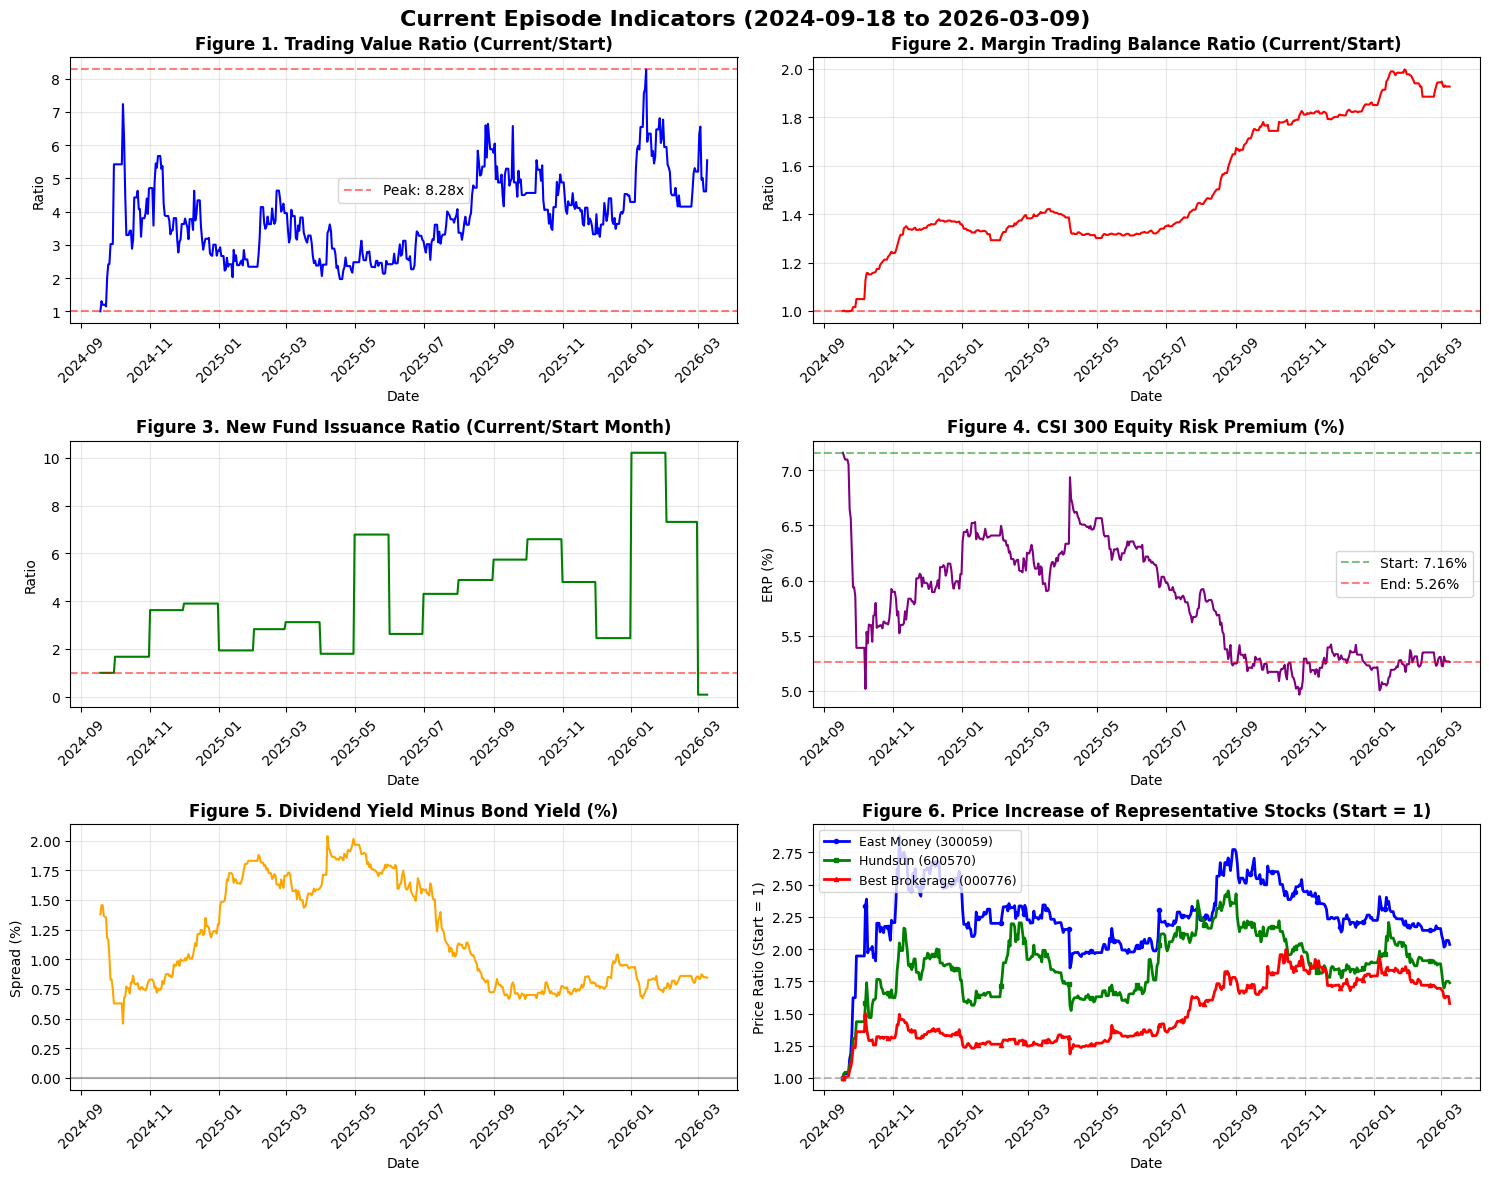

In [28]:
current_start = periods['current']['start']
current_end = periods['current']['end']
current_data = master[(master['date'] >= current_start) & (master['date'] <= current_end)].copy()

if len(current_data) > 0:
    current_data['trading_ratio'] = current_data['trading_value'] / current_data['trading_value'].iloc[0]
    current_data['margin_ratio'] = current_data['mt_balance'] / current_data['mt_balance'].iloc[0]
    current_data['erp'] = (1 / current_data['csi300_pe']) - (current_data['yield'] / 100)
    current_data['div_spread'] = (current_data['csi300_div_yield'] / 100) - (current_data['yield'] / 100)
    current_data['fund_ratio'] = np.nan
    for idx, row in current_data.iterrows():
        fund_val = get_monthly_fund_value(row['date'].year, row['date'].month)
        fund_start_val = get_monthly_fund_value(current_start.year, current_start.month)
        current_data.loc[idx, 'fund_ratio'] = fund_val / fund_start_val if fund_start_val != 0 else np.nan

    fig, axes = plt.subplots(3, 2, figsize=(15, 12))
    fig.suptitle('Current Episode Indicators (2024-09-18 to 2026-03-09)', fontsize=16, fontweight='bold')

    axes[0, 0].plot(current_data['date'], current_data['trading_ratio'], 'b-', linewidth=1.5)
    axes[0, 0].set_title('Figure 1. Trading Value Ratio (Current/Start)', fontweight='bold')
    axes[0, 0].set_xlabel('Date')
    axes[0, 0].set_ylabel('Ratio')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].axhline(y=1, color='r', linestyle='--', alpha=0.5)
    axes[0, 0].axhline(y=results_df.loc['Max Trading Value Ratio', 'current'],
                       color='r', linestyle='--', alpha=0.5,
                       label=f"Peak: {results_df.loc['Max Trading Value Ratio', 'current']:.2f}x")
    axes[0, 0].legend()
    axes[0, 0].tick_params(axis='x', rotation=45)

    axes[0, 1].plot(current_data['date'], current_data['margin_ratio'], 'r-', linewidth=1.5)
    axes[0, 1].set_title('Figure 2. Margin Trading Balance Ratio (Current/Start)', fontweight='bold')
    axes[0, 1].set_xlabel('Date')
    axes[0, 1].set_ylabel('Ratio')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].axhline(y=1, color='r', linestyle='--', alpha=0.5)
    axes[0, 1].tick_params(axis='x', rotation=45)

    axes[1, 0].plot(current_data['date'], current_data['fund_ratio'], 'g-', linewidth=1.5)
    axes[1, 0].set_title('Figure 3. New Fund Issuance Ratio (Current/Start Month)', fontweight='bold')
    axes[1, 0].set_xlabel('Date')
    axes[1, 0].set_ylabel('Ratio')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].axhline(y=1, color='r', linestyle='--', alpha=0.5)
    axes[1, 0].tick_params(axis='x', rotation=45)

    axes[1, 1].plot(current_data['date'], current_data['erp'] * 100, 'purple', linewidth=1.5)
    axes[1, 1].set_title('Figure 4. CSI 300 Equity Risk Premium (%)', fontweight='bold')
    axes[1, 1].set_xlabel('Date')
    axes[1, 1].set_ylabel('ERP (%)')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].axhline(y=results_df.loc['ERP Start (%)', 'current'],
                       color='g', linestyle='--', alpha=0.5,
                       label=f"Start: {results_df.loc['ERP Start (%)', 'current']:.2f}%")
    axes[1, 1].axhline(y=results_df.loc['ERP End (%)', 'current'],
                       color='r', linestyle='--', alpha=0.5,
                       label=f"End: {results_df.loc['ERP End (%)', 'current']:.2f}%")
    axes[1, 1].legend()
    axes[1, 1].tick_params(axis='x', rotation=45)

    axes[2, 0].plot(current_data['date'], current_data['div_spread'] * 100, 'orange', linewidth=1.5)
    axes[2, 0].set_title('Figure 5. Dividend Yield Minus Bond Yield (%)', fontweight='bold')
    axes[2, 0].set_xlabel('Date')
    axes[2, 0].set_ylabel('Spread (%)')
    axes[2, 0].grid(True, alpha=0.3)
    axes[2, 0].axhline(y=0, color='black', linestyle='-', alpha=0.3)
    axes[2, 0].tick_params(axis='x', rotation=45)

    if 'east_money_price' in current_data.columns:
      east_money_start = current_data['east_money_price'].iloc[0]
      current_data['east_money_ratio'] = current_data['east_money_price'] / east_money_start

    if 'hundsun_price' in current_data.columns:
      hundsun_start = current_data['hundsun_price'].iloc[0]
      current_data['hundsun_ratio'] = current_data['hundsun_price'] / hundsun_start

    axes[2, 1].plot(current_data['date'], current_data['east_money_ratio'],
                label='East Money (300059)',
                linewidth=2, marker='o', markersize=3, markevery=20, color='blue')

    axes[2, 1].plot(current_data['date'], current_data['hundsun_ratio'],
                label='Hundsun (600570)',
                linewidth=2, marker='s', markersize=3, markevery=20, color='green')

    if best_brokerage_data is not None:
      brokerage_current = best_brokerage_data[
        (best_brokerage_data['date'] >= current_start) &
        (best_brokerage_data['date'] <= current_end)
      ].copy()

      current_data = current_data.merge(
        brokerage_current,
        on='date',
        how='left'
      )

      if 'brokerage_price' in current_data.columns:
        brokerage_start = current_data['brokerage_price'].dropna().iloc[0]
        current_data['brokerage_price'] = current_data['brokerage_price'].ffill()
        current_data['brokerage_ratio'] = current_data['brokerage_price'] / brokerage_start

    if 'brokerage_ratio' in current_data.columns:
      axes[2, 1].plot(current_data['date'], current_data['brokerage_ratio'],
                    label=f'Best Brokerage ({best_brokerage_code})',
                    linewidth=2, marker='^', markersize=3, markevery=20, color='red')

    axes[2, 1].set_title('Figure 6. Price Increase of Representative Stocks (Start = 1)',
                     fontsize=12, fontweight='bold')
    axes[2, 1].set_xlabel('Date')
    axes[2, 1].set_ylabel('Price Ratio (Start = 1)')
    axes[2, 1].legend(loc='upper left', fontsize=9)
    axes[2, 1].grid(True, alpha=0.3)
    axes[2, 1].axhline(y=1, color='gray', linestyle='--', alpha=0.5)
    axes[2, 1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('current_episode_indicators.png', dpi=300, bbox_inches='tight')
    plt.show()